# Estilos de inversión en el S&P 500 · ACP y K-Means

Taller individual · Machine Learning aplicado a Economía y Finanzas · PUJ Cali
Camila Andrea Granja Castro

Este cuaderno recorre el mismo análisis que la aplicación de Streamlit (`app.py`), con las mismas funciones de `analisis.py`. Sirve para revisar el código paso a paso y verificar las cifras del informe.

**Pregunta.** ¿Los datos financieros de las empresas del S&P 500, por sí solos, separan estilos de inversión reconocibles (valor, crecimiento, dividendo, cíclicas)? ¿Esos grupos coinciden con los sectores?

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import analisis as an

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 160)

## 1. Datos originales

In [2]:
crudo = an.cargar_crudo()
print("Dimensión:", crudo.shape)
print("Celdas faltantes por columna:")
print(crudo.isna().sum()[crudo.isna().sum() > 0])
crudo.head()

Dimensión: (503, 15)
Celdas faltantes por columna:
Price             17
Price/Earnings    40
Dividend Yield    17
Earnings/Share    17
52 Week Low       17
52 Week High      17
Market Cap        17
EBITDA            43
Price/Sales       17
Price/Book        17
dtype: int64


,Symbol,Name,Subindustria,Price,Price/Earnings,Dividend Yield,Earnings/Share,52 Week Low,52 Week High,Market Cap,EBITDA,Price/Sales,Price/Book,SEC Filings,Sector
0,MMM,3M,Industrial Conglomerates,181.680,27.403,0.017,6.630,139.340,196.900,"93,879,427,072.000","6,497,999,872.000",3.718,22.747,http://www.sec.gov/cgi-bin/browse-edgar?action...,Industrial
1,AOS,A. O. Smith,Building Products,63.900,17.949,0.024,3.560,54.160,81.870,"8,583,620,608.000","785,699,968.000",2.257,4.708,http://www.sec.gov/cgi-bin/browse-edgar?action...,Industrial
2,ABT,Abbott Laboratories,Health Care Equipment,107.450,40.093,0.023,2.680,81.970,132.030,"186,097,123,328.000","11,457,999,872.000",3.859,3.647,http://www.sec.gov/cgi-bin/browse-edgar?action...,Salud
3,ABBV,AbbVie,Biotechnology,294.550,50.697,0.024,5.810,190.750,302.930,"520,651,341,824.000","31,850,999,808.000",7.887,-113.594,http://www.sec.gov/cgi-bin/browse-edgar?action...,Salud
4,ACN,Accenture,IT Consulting & Other Services,247.700,18.267,0.027,13.560,118.150,291.090,"146,325,667,840.000","13,419,352,064.000",1.972,4.673,http://www.sec.gov/cgi-bin/browse-edgar?action...,Tecnología


In [3]:
crudo.describe().T

,count,mean,std,min,25%,50%,75%,max
Price,486.000,227.465,364.863,0.099,71.032,142.240,277.680,"5,793.360"
Price/Earnings,463.000,42.615,212.894,4.415,16.600,22.547,32.924,"4,464.200"
Dividend Yield,486.000,0.018,0.016,0.000,0.005,0.014,0.027,0.076
Earnings/Share,486.000,9.478,20.194,-80.010,2.552,5.940,11.268,358.020
52 Week Low,486.000,167.560,311.271,0.062,55.415,105.290,189.990,"5,501.010"
52 Week High,486.000,279.744,481.241,14.620,88.082,171.610,323.238,"8,200.000"
Market Cap,486.000,"140,163,177,727.613","447,844,955,788.744","207,300.000","20,128,694,272.000","41,901,191,168.000","95,610,224,640.000","5,126,663,176,192.000"
EBITDA,460.000,"9,223,610,095.765","23,499,915,446.805","-1,783,000,064.000","1,830,286,944.000","3,516,209,536.000","7,304,750,080.000","205,690,994,688.000"
Price/Sales,486.000,4.315,4.788,0.020,1.614,3.058,5.646,53.025
Price/Book,486.000,2.053,46.075,-565.165,1.776,3.006,6.628,442.433


Diecisiete filas están vacías (empresas sin datos en Yahoo) y 26 empresas financieras no tienen EBITDA. Hay valores imposibles o extremos: un precio de 0,10 USD, un P/E de 4.464 y P/B negativos (patrimonio contable negativo).

## 2. Limpieza

In [4]:
datos, bitacora = an.limpiar(crudo)
print("Empresas que quedan:", len(datos))
bitacora[["Decisión", "Empresas", "Motivo"]]

Empresas que quedan: 482


,Decisión,Empresas,Motivo
0,Excluir empresas sin precio ni estados financi...,17,Yahoo Finance no devolvió datos (empresas adqu...
1,Excluir registros con datos inconsistentes,1,"PARA reporta precio de 0,10 USD, máximo de 52 ..."
2,Conservar una sola clase de acción por empresa,3,"GOOG/GOOGL, FOX/FOXA y NWS/NWSA son la misma e..."
3,No usar EBITDA,0,"26 empresas, todas del sector financiero, no r..."
4,Excluir identificadores y texto del modelo,0,"Symbol, Name, SEC Filings, Subindustria y Sect..."


## 3. Variables de análisis

In [5]:
identificacion, variables = an.construir_variables(datos)
print("Faltantes después de construir las variables:", int(variables.isna().sum().sum()))
variables.describe().T

Faltantes después de construir las variables: 0


,count,mean,std,min,25%,50%,75%,max
tamano_log,482.000,10.682,0.526,8.910,10.306,10.624,10.981,12.710
rend_utilidades,482.000,0.031,0.292,-6.302,0.029,0.042,0.059,0.227
libro_mercado,482.000,0.323,0.291,-0.347,0.110,0.270,0.464,1.991
ventas_precio,482.000,0.591,0.756,0.019,0.177,0.326,0.618,4.953
rend_dividendo,482.000,0.018,0.016,0.000,0.005,0.014,0.027,0.076
margen_neto,482.000,0.144,0.166,-1.821,0.071,0.129,0.215,0.733
rango_52s,482.000,0.379,0.131,0.164,0.289,0.354,0.441,0.921
posicion_52s,482.000,0.585,0.277,0.002,0.365,0.614,0.837,0.999


In [6]:
recortadas, resumen = an.winsorizar(variables, 0.01)
resumen

,Límite inferior,Límite superior,Valores recortados
tamano_log,9.759,12.250,10
rend_utilidades,-0.162,0.141,10
libro_mercado,-0.143,1.228,10
ventas_precio,0.054,3.946,10
rend_dividendo,0.000,0.062,5
margen_neto,-0.146,0.587,10
rango_52s,0.181,0.775,10
posicion_52s,0.006,0.991,10


In [7]:
recortadas.corr().round(2)

,tamano_log,rend_utilidades,libro_mercado,ventas_precio,rend_dividendo,margen_neto,rango_52s,posicion_52s
tamano_log,1.000,0.000,-0.360,-0.280,-0.140,0.340,-0.060,0.130
rend_utilidades,0.000,1.000,0.110,0.010,0.020,0.360,-0.070,-0.050
libro_mercado,-0.360,0.110,1.000,0.340,0.390,-0.240,-0.110,-0.210
ventas_precio,-0.280,0.010,0.340,1.000,0.110,-0.500,0.160,-0.100
rend_dividendo,-0.140,0.020,0.390,0.110,1.000,-0.020,-0.320,-0.090
margen_neto,0.340,0.360,-0.240,-0.500,-0.020,1.000,-0.120,0.030
rango_52s,-0.060,-0.070,-0.110,0.160,-0.320,-0.120,1.000,-0.290
posicion_52s,0.130,-0.050,-0.210,-0.100,-0.090,0.030,-0.290,1.000


Las correlaciones son moderadas (la mayor en valor absoluto es −0,50, entre ventas a precio y margen neto). Hay redundancia que el ACP puede aprovechar, pero ninguna variable repite a otra.

## 4. Estandarización y ACP

In [8]:
z = an.estandarizar(recortadas)
acp = an.ajustar_acp(z)
acp["varianza"]

,Componente,Valor propio,Varianza explicada,Varianza acumulada
0,CP1,2.196,0.274,0.274
1,CP2,1.556,0.194,0.468
2,CP3,1.263,0.158,0.626
3,CP4,0.920,0.115,0.740
4,CP5,0.731,0.091,0.832
5,CP6,0.520,0.065,0.896
6,CP7,0.483,0.060,0.957
7,CP8,0.348,0.043,1.000


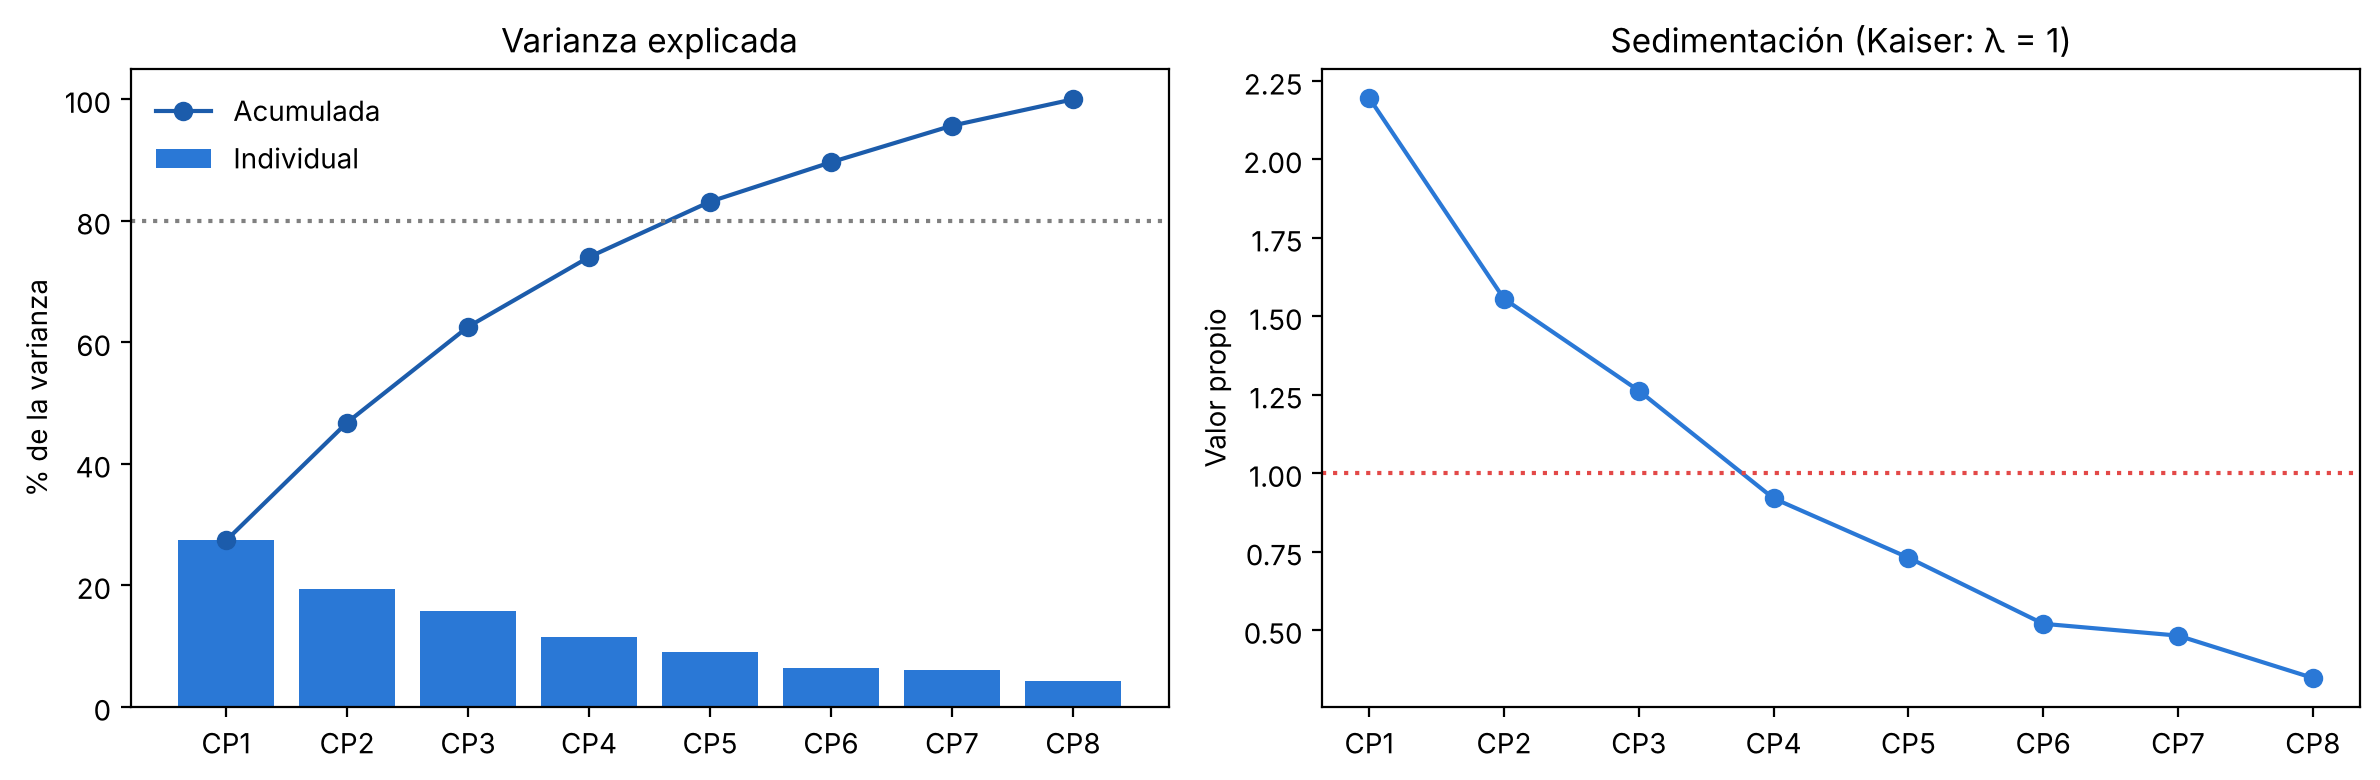

{'kaiser': 3, 'acumulada': 5}


In [9]:
v = acp["varianza"]
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].bar(v["Componente"], v["Varianza explicada"] * 100, color="#2a78d6", label="Individual")
ejes[0].plot(v["Componente"], v["Varianza acumulada"] * 100, marker="o", color="#1c5cab", label="Acumulada")
ejes[0].axhline(80, ls=":", color="gray")
ejes[0].set_ylabel("% de la varianza"); ejes[0].set_title("Varianza explicada"); ejes[0].legend(frameon=False)
ejes[1].plot(v["Componente"], v["Valor propio"], marker="o", color="#2a78d6")
ejes[1].axhline(1, ls=":", color="#e34948"); ejes[1].set_title("Sedimentación (Kaiser: λ = 1)")
ejes[1].set_ylabel("Valor propio")
plt.tight_layout(); plt.show()
print(an.sugerir_componentes(v))

In [10]:
acp["correlaciones"].iloc[:, :4].round(2)

,CP1,CP2,CP3,CP4
tamano_log,-0.660,0.020,0.040,-0.170
rend_utilidades,-0.130,-0.440,-0.620,0.580
libro_mercado,0.690,-0.430,-0.140,-0.020
ventas_precio,0.720,0.170,0.010,0.350
rend_dividendo,0.370,-0.680,0.100,-0.380
margen_neto,-0.700,-0.380,-0.400,-0.050
rango_52s,0.120,0.730,-0.460,-0.030
posicion_52s,-0.320,-0.110,0.690,0.530


**Lectura de los componentes**

- **CP1 (27,4 %) · valor frente a calidad.** Positivo: ventas a precio (0,72) y libro a mercado (0,69). Negativo: margen neto (−0,70) y tamaño (−0,66).
- **CP2 (19,4 %) · riesgo frente a ingreso.** Positivo: amplitud del rango de 52 semanas (0,73). Negativo: dividendo (−0,68), rendimiento de utilidades (−0,44) y libro a mercado (−0,43).
- **CP3 (15,8 %) · momento.** Positivo: posición en el rango de 52 semanas (0,69). Negativo: rendimiento de utilidades (−0,62) y amplitud del rango (−0,46).

Kaiser sugiere tres componentes (62,6 %); el criterio del 80 % pide cinco. Se conservan tres: el cuarto tiene λ = 0,92, ya no resume más que una variable original, y la sección 5 muestra que con tres componentes los grupos son más compactos y estables.

## 5. K-Means

In [11]:
for n in (3, 5):
    print(f"--- {n} componentes ---")
    print(an.evaluar_k(acp["puntajes"].iloc[:, :n]).round(3).to_string(index=False))

--- 3 componentes ---


 K   Inercia  Silueta  Grupo más pequeño
 2 1,778.923    0.268                196
 3 1,393.562    0.277                113
 4 1,139.617    0.290                 62
 5 1,011.802    0.238                 54
 6   904.004    0.244                 22
 7   822.043    0.251                 21
 8   756.716    0.257                 14
 9   690.267    0.250                  8
10   635.927    0.256                 11
--- 5 componentes ---


 K   Inercia  Silueta  Grupo más pequeño
 2 2,572.378    0.222                175
 3 2,181.170    0.203                 95
 4 1,894.303    0.204                 63
 5 1,664.550    0.219                  8
 6 1,474.037    0.199                 12
 7 1,373.384    0.191                 11
 8 1,284.340    0.191                  9
 9 1,217.929    0.189                  9
10 1,157.791    0.188                  9


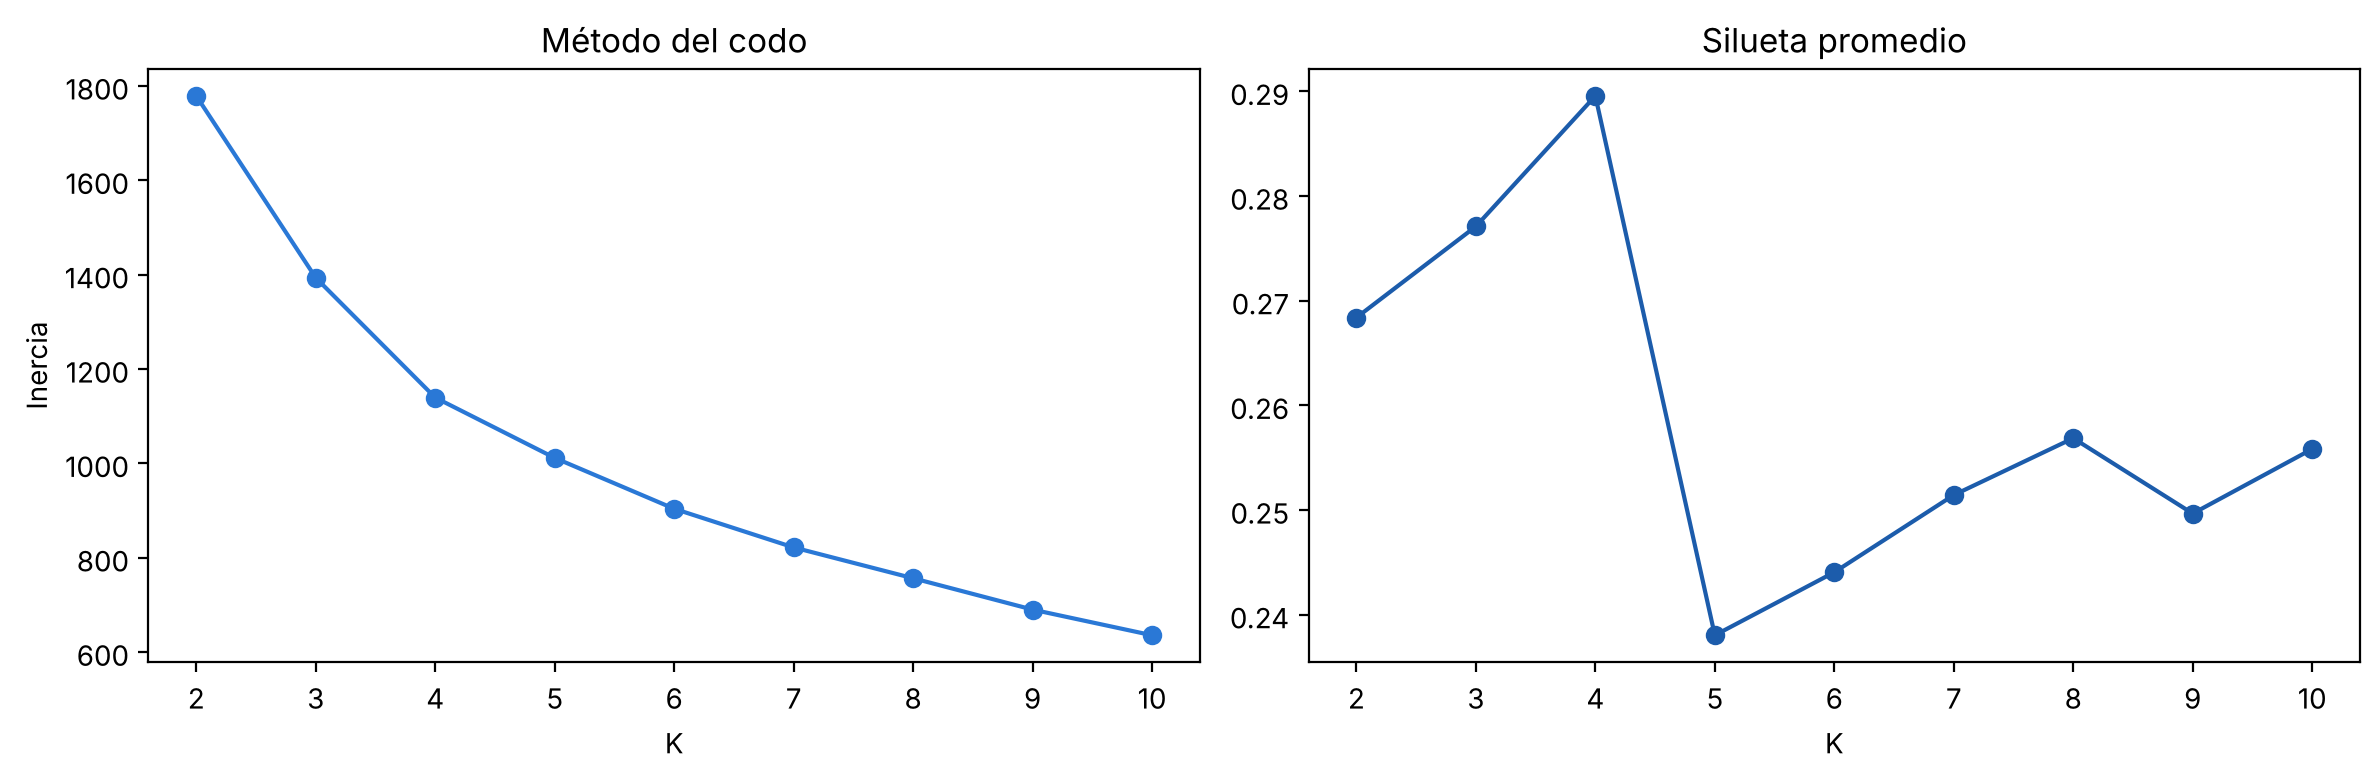

K = 3: ARI medio 0.70, mínimo 0.24
K = 4: ARI medio 0.95, mínimo 0.88


In [12]:
matriz = acp["puntajes"].iloc[:, :3]
evaluacion = an.evaluar_k(matriz)
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(evaluacion["K"], evaluacion["Inercia"], marker="o", color="#2a78d6")
ejes[0].set_title("Método del codo"); ejes[0].set_xlabel("K"); ejes[0].set_ylabel("Inercia")
ejes[1].plot(evaluacion["K"], evaluacion["Silueta"], marker="o", color="#1c5cab")
ejes[1].set_title("Silueta promedio"); ejes[1].set_xlabel("K")
plt.tight_layout(); plt.show()

for k in (3, 4):
    media, minimo = an.estabilidad(matriz, k)
    print(f"K = {k}: ARI medio {media:.2f}, mínimo {minimo:.2f}")

K = 4 tiene la mayor silueta (0,290) y es muy estable entre semillas (ARI medio 0,95). K = 3 es inestable (ARI mínimo 0,24). Una silueta de 0,29 indica estructura débil a moderada: hay grupos, pero con fronteras que se tocan.

In [13]:
km = an.ajustar_kmeans(matriz, 4)
grupo = km["grupo"]
print(grupo.value_counts().sort_index())
print("Silueta media por grupo:")
print(km["silueta"].groupby(grupo).mean().round(3))
print("Empresas con silueta negativa:", int((km["silueta"] < 0).sum()))

Grupo
A    209
B    106
C    105
D     62
Name: count, dtype: int64
Silueta media por grupo:
Grupo
A   0.343
B   0.300
C   0.239
D   0.178
Name: Silueta, dtype: float64
Empresas con silueta negativa: 16


## 6. Perfil de los grupos con las variables originales

In [14]:
an.perfiles(variables, grupo)

Grupo,A,B,C,D,Total
tamano_log,10.869,10.498,10.543,10.289,10.624
rend_utilidades,0.035,0.065,0.048,0.029,0.042
libro_mercado,0.143,0.538,0.208,0.570,0.270
ventas_precio,0.214,0.363,0.363,1.529,0.326
rend_dividendo,0.011,0.032,0.006,0.022,0.014
margen_neto,0.158,0.176,0.108,0.013,0.129
rango_52s,0.338,0.258,0.531,0.387,0.354
posicion_52s,0.790,0.571,0.266,0.579,0.614


In [15]:
an.perfiles_z(z, grupo).round(2)

Grupo,A,B,C,D
tamano_log,0.440,-0.270,-0.140,-0.770
rend_utilidades,-0.170,0.690,0.190,-0.920
libro_mercado,-0.580,0.890,-0.280,0.910
ventas_precio,-0.430,-0.150,-0.030,1.750
rend_dividendo,-0.300,0.990,-0.620,0.370
margen_neto,0.280,0.300,-0.120,-1.240
rango_52s,-0.310,-0.750,1.220,0.260
posicion_52s,0.520,-0.120,-0.880,-0.060


In [16]:
(an.composicion_sectorial(identificacion['Sector'], grupo) * 100).round(0)

Grupo,A,B,C,D
Sector,,,,
Comunicaciones,47.000,24.000,12.000,18.000
Consumo básico,43.000,17.000,0.000,40.000
Consumo discrecional,50.000,6.000,22.000,22.000
Energía,32.000,37.000,32.000,0.000
Financiero,46.000,49.000,1.000,3.000
Industrial,53.000,5.000,34.000,8.000
Inmobiliario,35.000,52.000,10.000,3.000
Materiales,29.000,18.000,18.000,36.000
Salud,58.000,3.000,17.000,22.000


In [17]:
tabla = identificacion.assign(Grupo=grupo, Cap=datos["Market Cap"] / 1e9)
for g in sorted(grupo.unique()):
    print(g, tabla[tabla.Grupo == g].sort_values("Cap", ascending=False)["Ticker"].head(10).tolist())

A ['AAPL', 'MSFT', 'NVDA', 'GOOGL', 'AMZN', 'META', 'AVGO', 'TSLA', 'LLY', 'WMT']
B ['BAC', 'GS', 'WFC', 'C', 'VZ', 'TMUS', 'NEE', 'PFE', 'T', 'PLD']
C ['AMD', 'MU', 'ORCL', 'INTC', 'AMAT', 'LRCX', 'CAT', 'PANW', 'NFLX', 'CRWD']
D ['MCK', 'CVS', 'ELV', 'CI', 'WBD', 'TGT', 'GM', 'COR', 'CAH', 'HUM']


## 7. Conclusiones

- **A · Grandes de calidad y momento (209).** Las más grandes, caras frente a patrimonio y ventas, margen alto, cerca de su máximo anual. Apple, Microsoft, Nvidia, Alphabet, Amazon, Meta, Lilly.
- **B · Valor y dividendo defensivo (106).** Dividendo alto, baratas frente a utilidades y patrimonio, poca volatilidad. 84 % de los servicios públicos, la mitad del sector financiero y del inmobiliario.
- **C · Alta volatilidad, lejos del máximo (105).** Mayor recorrido anual, en la parte baja de su rango, casi sin dividendo. 57 % de la tecnología (semiconductores) e industriales cíclicas.
- **D · Volumen con margen estrecho (62).** Muchas ventas por dólar de capitalización, margen neto de 1,3 %. Distribuidoras farmacéuticas, aseguradoras de salud, minoristas y automotrices.

Los grupos cruzan los sectores: solo los servicios públicos concentran más del 60 % de sus empresas en un mismo grupo. Diversificar por sector no garantiza diversificar por estilo.

**Limitaciones.** Es un corte transversal (la posición y el rango de 52 semanas cambian a diario); los tres componentes dejan fuera el 37 % de la variación; K-Means supone grupos esféricos; las razones de bancos no son del todo comparables; faltan variables de crecimiento, apalancamiento y beta.